# NF-κB (+PPARG) log2FC heatmap — organoid Cd vs Mock across butyrate dose
### For Sara / poster — complementary to the co-infection heatmap

Reproduces the co-infection heatmap idea on the **organoid C. difficile / butyrate** dataset:
**log2 fold-change** of the NF-κB(+PPARG) genes of interest for three contrasts —
**Cd vs Mock at 0, 5, 10 mM butyrate** — read straight from the DE tables (no recompute).

Diverging colour centred at 0 (red = up in Cd, blue = down), significance dots from padj.
Also exports the underlying log2FC+padj table as CSV. Kernel: any pandas/matplotlib env.

In [1]:
import pandas as pd, numpy as np, os, re
from pathlib import Path
import matplotlib as mpl, matplotlib.pyplot as plt
A04 = Path(os.environ.get('A04_PROJ', str(Path.home()/'Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate')))
TAB = A04/'results/tables'; OUT = A04/'results/overview_for_sara'; OUT.mkdir(parents=True, exist_ok=True)
mpl.rcParams.update({'font.family':'sans-serif','font.sans-serif':['Helvetica','Arial','DejaVu Sans'],
  'figure.dpi':130,'savefig.dpi':300,'savefig.bbox':'tight'})

# same NF-κB(+PPARG) gene set as the overview notebook (Hallmark ∪ KEGG ∪ Reactome union fallback + PPARG)
NFKB = set('''NFKB1 NFKB2 RELA RELB REL NFKBIA NFKBIB NFKBIE NFKBIZ IKBKB IKBKG CHUK
  TNF TNFAIP3 TNFAIP2 TRAF1 TRAF2 TRAF3 TRAF6 TRADD RIPK1 RIPK2 MAP3K7 TAB1 TAB2 TAB3
  IRAK1 IRAK2 IRAK4 MYD88 TLR2 TLR4 CD14 LY96 BIRC2 BIRC3 XIAP CFLAR
  CXCL1 CXCL2 CXCL3 CXCL8 CCL20 CCL2 CCL5 IL1B IL6 PTGS2 NFKBIL1 BCL3 PLAU ICAM1 VCAM1
  LTA LTB CD40 CD40LG TNFRSF1A TNFRSF1B IKBKE TBK1 GADD45B EDN1 SOD2 CXCL10'''.split())
NFKB.add('PPARG')
print('genes of interest:', len(NFKB))

genes of interest: 66


In [2]:
# ---- read the 3 DE tables, pull log2FC + padj per gene ----
def load_de(fname):
    f=TAB/fname
    if not f.exists(): raise FileNotFoundError(f)
    d=pd.read_csv(f,index_col=0)
    for col in ['gene_name','symbol','Gene','gene']:
        if col in d.columns: d=d.set_index(col); break
    d.index=[re.sub(r'\..*','',str(i)) for i in d.index]
    # collapse duplicate gene symbols (multiple Ensembl IDs -> one symbol): keep most-significant row
    if d.index.duplicated().any():
        pcol='padj' if 'padj' in d.columns else ('pvalue' if 'pvalue' in d.columns else None)
        if pcol is not None:
            d=d.assign(_p=d[pcol].fillna(1.0)).sort_values('_p').loc[~d.index.duplicated(keep='first')].drop(columns='_p')
        else:
            d=d.loc[~d.index.duplicated(keep='first')]
    return d
specs=[('DE_Cd_vs_Mock_0mM.csv','Cd vs Mock · 0 mM'),
       ('DE_Cd_vs_Mock_5mM.csv','Cd vs Mock · 5 mM'),
       ('DE_Cd_vs_Mock_10mM.csv','Cd vs Mock · 10 mM')]
lfc={}; padj={}
for fn,label in specs:
    d=load_de(fn)
    lfc[label]=d['log2FoldChange'] if 'log2FoldChange' in d.columns else d.get('log2FC')
    padj[label]=d['padj'] if 'padj' in d.columns else d.get('pvalue')
LFC=pd.DataFrame(lfc); PADJ=pd.DataFrame(padj)
present=[g for g in NFKB if g in LFC.index]
missing=sorted(g for g in NFKB if g not in LFC.index)
print(f'genes present: {len(present)} | missing: {len(missing)} -> {missing[:10]}')
M=LFC.loc[present].copy(); P=PADJ.loc[present].copy()
# order rows by the 10 mM column (or by 0mM magnitude) so the dose pattern reads top-to-bottom
M=M.loc[M['Cd vs Mock · 0 mM'].sort_values(ascending=False).index]
P=P.loc[M.index]
print(M.round(2).head())

genes present: 59 | missing: 7 -> ['CCL2', 'CD40LG', 'IL6', 'LTA', 'LY96', 'PTGS2', 'VCAM1']
        Cd vs Mock · 0 mM  Cd vs Mock · 5 mM  Cd vs Mock · 10 mM
CCL20                5.83               5.75                5.71
TNF                  5.75               5.79                2.84
CXCL8                4.09               4.09                1.90
NFKBIZ               3.63               2.62                1.77
BIRC3                3.62               3.06                3.00


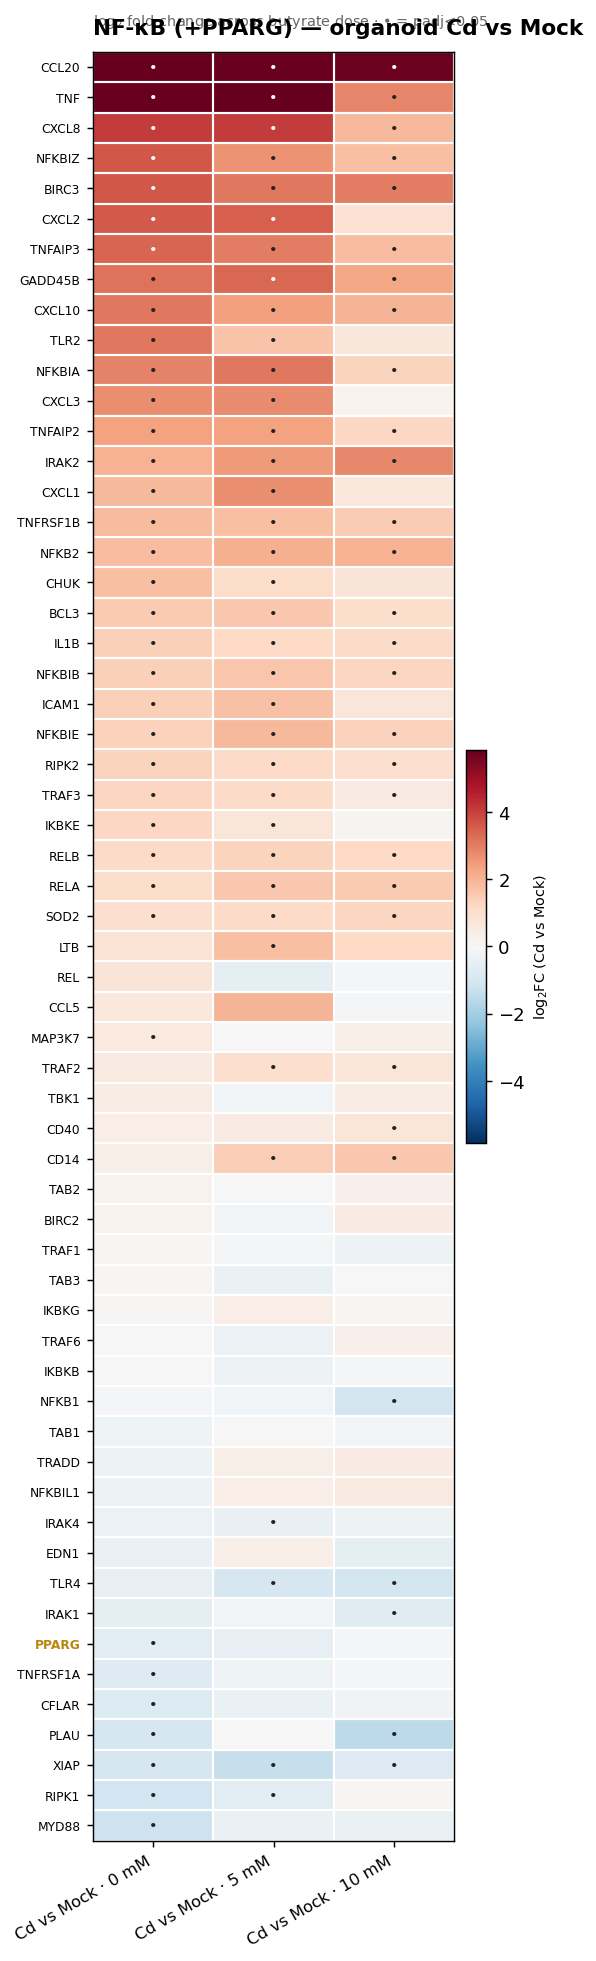

wrote /home/job37yv/Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate/results/overview_for_sara/heatmap_NFkB_PPARG_organoid_log2FC.png


In [3]:
# ---- heatmap (log2FC, diverging, significance dots) ----
cols=[l for _,l in specs]
vmax=float(np.nanmax(np.abs(M.values))); vmax=max(1.0, min(vmax,6))
fig,ax=plt.subplots(figsize=(4.4, max(6,0.24*len(M)+1)))
im=ax.imshow(M.values, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=30, ha='right', fontsize=9)
ax.set_yticks(range(len(M))); ax.set_yticklabels(M.index, fontsize=6.8)
# significance dots (padj<0.05) as a small marker
for i in range(len(M)):
    for j in range(len(cols)):
        p=P.values[i,j]
        if not pd.isna(p) and p<0.05:
            ax.text(j,i,'•',ha='center',va='center',fontsize=8,
                    color='white' if abs(M.values[i,j])>vmax*0.55 else '#222')
ax.set_xticks(np.arange(-.5,len(cols),1),minor=True); ax.set_yticks(np.arange(-.5,len(M),1),minor=True)
ax.grid(which='minor',color='white',lw=1.2); ax.tick_params(which='minor',length=0)
ax.set_title('NF-κB (+PPARG) — organoid Cd vs Mock', fontsize=12, fontweight='bold', loc='left', pad=10)
ax.text(0,1.015,'log$_2$ fold-change across butyrate dose · • = padj<0.05', transform=ax.transAxes, fontsize=8, color='#666')
cb=fig.colorbar(im,ax=ax,fraction=0.05,pad=0.03); cb.set_label('log$_2$FC (Cd vs Mock)',fontsize=8)
if 'PPARG' in M.index:
    yi=list(M.index).index('PPARG'); ax.get_yticklabels()[yi].set_color('#b8860b'); ax.get_yticklabels()[yi].set_fontweight('bold')
plt.tight_layout(); fig.savefig(OUT/'heatmap_NFkB_PPARG_organoid_log2FC.png'); plt.show()
print('wrote', OUT/'heatmap_NFkB_PPARG_organoid_log2FC.png')

In [4]:
# ---- export the underlying data as CSV (log2FC + padj per gene per dose) ----
exp=M.copy(); exp.columns=[c2+' log2FC' for c2 in exp.columns]
for _,label in specs: exp[label+' padj']=P[label]
exp.index.name='gene_symbol'
csv=OUT/'heatmap_NFkB_PPARG_organoid_log2FC.csv'; exp.round(4).to_csv(csv)
print('wrote', csv); print(exp.round(3).head())

wrote /home/job37yv/Projects_shared/DECIDE_A04_CdiffOrganoid_Butyrate/results/overview_for_sara/heatmap_NFkB_PPARG_organoid_log2FC.csv
             Cd vs Mock · 0 mM log2FC  Cd vs Mock · 5 mM log2FC  \
gene_symbol                                                       
CCL20                           5.831                     5.747   
TNF                             5.754                     5.792   
CXCL8                           4.090                     4.086   
NFKBIZ                          3.628                     2.622   
BIRC3                           3.619                     3.059   

             Cd vs Mock · 10 mM log2FC  Cd vs Mock · 0 mM padj  \
gene_symbol                                                      
CCL20                            5.708                     0.0   
TNF                              2.838                     0.0   
CXCL8                            1.900                     0.0   
NFKBIZ                           1.772                     0.0   

## Notes for Sara
- Same genes of interest as the co-infection NF-κB(+PPARG) figure; here it's **log2FC** (Cd vs Mock) at
  each butyrate dose, so it reads as a dose-response and is directly comparable to the co-infection heatmap.
- Red = induced by Cd, blue = repressed; the expected story is the chemokine block cooling from 0→10 mM.
- • marks padj<0.05. Underlying numbers exported alongside as CSV.
- `missing` (printed above) are genes not detected / not in the annotation — reported honestly, not shown as 0.